# Six queues and what one more worker changes

You arrive at a checkout with a small basket. The cashier is halfway through scanning somebody else's groceries. Even if your own checkout will take less than a minute, you still have to wait for the work already in progress. From the shopper's side, there are two clocks worth noticing. One runs until the cashier starts on your basket. The other runs until you pay and leave.

If you are managing the shop, the difference tells you which problem you are trying to solve. A faster card terminal might shorten payment for everyone. Opening a second counter lets another basket start while the first is still being scanned. The useful outcome in either case is that people get through the store without waiting long during a rush. The manager also needs to know whether the change is worth providing for the whole shift.

### An illustrative checkout

Imagine Ana arrives when the counter opens. Her basket takes four minutes. Ben arrives at minute 2 and needs three minutes. Chen arrives at minute 3 and needs one. Everyone takes the next available cashier in order of arrival.

With one cashier, Ben starts at minute 4 and waits two minutes. Chen starts at minute 7 and waits four minutes. A quick basket can still spend more of its time waiting than being scanned.

With a second cashier, Ben starts as soon as he arrives. When Chen shows up, both cashiers are busy. Ana finishes at minute 4, so Chen waits one minute. Even the larger crew can have a line. It depends on who turns up close together and how much work is already underway.

Waiting forms the **queue**. In some settings you can see it from across the room. A lab sample can wait on a rack, while a software ticket can wait for a reviewer after somebody has finished writing its code. In both cases you can follow the same two clocks as at the checkout. A job that waits twice has two stretches of queue time.

A short burst of arrivals can produce a long queue even when there is spare capacity later. Finishing each job takes time. Once a line forms, new arrivals have to share capacity with work that is already waiting. The line can remain visible after the burst passes.

A real operation can compare two staffing levels on two different days. That comparison also changes the arrivals, the jobs and their timing. A simulation can replay the same day with one more resource and keep the other inputs fixed. Replaying makes an added worker's effect easier to isolate in the model. Repeating the comparison on many synthetic days shows how much the result depends on the particular day you drew.

The question here is how much one extra worker or analyzer changes long waits, unfinished work and, for callers, hanging up. The answer can depend on where the resource goes and what the service does when somebody has to wait.

## Study summary

The study compares current staffing with one added resource in six fictional settings. Each setting uses 240 independently generated operating periods. The same people or jobs, arrival times and work requirements go to both staffing policies. Five settings admit work for one eight-hour shift. The software team admits tickets for 40 staffed hours.

To describe a long wait, take the **90th percentile**, or **p90**, of the queue times for people or jobs that eventually receive service. If a shift's p90 is 10 minutes, about nine out of ten served jobs waited 10 minutes or less. The study calculates this cutoff separately for every period and averages the cutoffs. Waits of zero count. After a job starts service, time spent receiving service stays off this clock.

The added resource shortened the period p90 in all 240 pairs in each setting. At checkout, the average shift p90 fell from 49.7 to 3.7 minutes. A second reviewer cut it from 11.2 to 2.1 staffed hours for software tickets. At the bank, the wait among answered callers fell from 4.5 to 2.9 minutes, and the share of all callers who hung up fell from 19.5% to 11.1%. These numbers describe the workloads and rules we gave the simulation. A shift with different arrival patterns or service times could see a different effect.

## Contents

- [1. The six settings and their inputs](#1-the-six-settings-and-their-inputs)
- [2. How the clock moves](#2-how-the-clock-moves)
- [3. Long waits and work left at closing](#3-long-waits-and-work-left-at-closing)
- [4. Six operating periods up close](#4-six-operating-periods-up-close)
- [5. What the comparison can support](#5-what-the-comparison-can-support)
- [6. How to reproduce](#6-how-to-reproduce)
- [7. Future work and further reading](#7-future-work-and-further-reading)

```mermaid
flowchart LR
    A["6 settings<br/>arrival windows, stage times and queue rules"] --> B["Generate 240 input periods per setting<br/>1,440 lists of paired inputs"]
    B --> C["Run each list twice<br/>baseline and one extra resource"]
    C --> D["2,880 runs<br/>dispatch and record every job"]
    D --> E["Measure wait, abandonment and close backlog<br/>compare the 240 matched periods per setting"]
    E --> F["6 comparisons and 6 queue timelines<br/>saved results and period 1 job records"]
```

A shipment gets an arrival time, a primary inspection duration and a draw that decides whether it visits secondary inspection. If it is referred, it also gets a secondary duration. Those values go into both simulations. When the shipment is done, its wait before primary and, where applicable, its wait before secondary are added. Whether it was still in either stage at closing goes into a second measure. The first generated period of each setting supplies the timeline examples. This choice keeps the examples fixed even when other periods happen to show a clearer difference.

## 1. The six settings and their inputs

A setting specifies when work arrives, the order of the stages, what can wait at each stage and which resource to add. A **stage** is a place where a job waits for a particular kind of service. A **resource** is one worker or machine that provides that service. The implementation and the review of a ticket are separate stages because different people provide those services. There is one waiting line per stage, shared by the workers assigned to it.

The configurations below are designed to expose different ways a line can form. The timings and staffing levels are scenario assumptions. The experiment uses synthetic draws throughout and has no service records from any organization. The large waits in some baselines reflect an intentionally tight setup during the rush.

| Setting and unit of work | Baseline route and resources | One added resource | How the line works |
| --- | --- | --- | --- |
| Blood testing lab, one specimen | One accession worker records and prepares it, then one analyzer processes a batch | Second analyzer | Up to eight ready samples run together. An idle analyzer starts a full batch immediately, or a partial batch once the oldest ready sample has waited 15 minutes. |
| Checkout counter, one shopper | One cashier scans the basket and takes payment | Second cashier | Shoppers in one common line go to the first free cashier in arrival order. |
| Software development, one ticket | Three developers implement work, then one reviewer checks it | Second reviewer | Urgent tickets precede routine tickets in both waiting lines. Work already underway runs to completion. |
| Bank call center, one call | Four agents take calls from a common line | Fifth agent | A waiting caller hangs up when a randomly assigned patience time expires. Calls already with an agent stay connected. |
| Passport office, one applicant | Two clerks check an application | Third clerk | A booked arrival goes ahead of a walk-in when both are waiting. An application already at a desk keeps its clerk. |
| Customs clearance, one shipment | Two primary officers check paperwork. Referred shipments join a separate queue for one inspector. | Second secondary inspector | All shipments go through primary. A fixed probability determines referral for each shipment. Both queues follow arrival order. |

The lab clock begins at specimen intake. It covers accession and the simulated analyzer run. The checkout clock begins when a shopper joins the line. The software clock starts when a ticket is filed and counts only staffed hours through completion of review. A call's clock begins as it reaches the agent queue and ends when the call is done or the caller hangs up. The passport clock stops when the desk transaction is complete. The customs clock stops when every required check is complete. These boundaries say what a reader can infer about each setting. A shorter passport desk wait, for example, gives no estimate of the time needed to issue a passport.

### How work arrives

Each operating period has three windows. The middle window has a higher specified arrival rate. The three windows are hours 0–2, 2–5 and 5–8 in the five shift-length settings, and staffed hours 0–16, 16–32 and 32–40 for tickets. The software windows use a single staffed clock, so hour 16 can be read as the end of two eight-hour workdays with nonworking time skipped.

| Setting | Random arrivals per hour, early / rush / late | Other input |
| --- | ---: | --- |
| Blood testing lab | 16 / 34 / 17 | The rate describes specimens arriving for accession. |
| Checkout counter | 8 / 18 / 9 | One basket per shopper. |
| Software development tickets | 0.90 / 1.55 / 1.00 | Each ticket independently has a 20% chance of being urgent. |
| Bank call center | 23 / 45 / 26 | Individual patience is exponential with an eight-minute mean. |
| Passport office | 4 / 9 / 6 | These are walk-in rates. One appointment arrives exactly every 10 minutes starting at opening, adding 48 fixed arrivals per shift. |
| Customs clearance counter | 13 / 25 / 15 | Each shipment independently has a 25% chance of needing secondary inspection. |

For a window with a rate of eight per hour and a duration of two hours, the number of arrivals has a mean of 16. The program draws a whole number from a Poisson distribution with that mean. It then puts that many arrivals at random points in the window. Two shifts can have the same count and have very different lines because of the gaps between the arrivals. Scheduled passport arrivals are placed at their exact appointment times. The rule gives bookings evenly spaced demand, while walk-ins can bunch around them.

The ratio of incoming work to capacity gives an initial reason to look for congestion. A cashier taking four minutes per basket could finish 15 per hour on average when kept busy. The simulated rush brings 18 per hour on average. A particular rush can be easier or harder than that calculation. The calculation also says little about how long a queue takes to clear once arrivals slow down. That is where the event paths help.

### How long the work takes

The service times for individual jobs use gamma distributions. A gamma draw is positive and can admit occasional long jobs. The mean sets the typical volume of work a stage receives. A **coefficient of variation** describes the spread as a fraction of the mean. For the cashier, 0.75 with a mean of four minutes gives a standard deviation of three minutes. Distinct stages draw independently in this model. The batch analyzer instead keeps the same 22-minute run time at every batch size.

| Stage | Mean service (minutes) | Coefficient of variation |
| --- | ---: | ---: |
| Lab accession | 1.15 per sample | 0.50 |
| Lab analyzer | 22 per batch of up to 8 samples | 0 |
| Checkout | 4 per shopper | 0.75 |
| Ticket implementation | 82 per ticket | 1.00 |
| Ticket review | 55 per ticket | 0.90 |
| Bank agent | 7 per call | 1.00 |
| Passport application desk | 9.5 per applicant | 0.55 |
| Primary customs check | 4 per shipment | 0.60 |
| Secondary customs inspection | 15 per referred shipment | 0.80 |

For a caller, patience is a separate clock that starts on entering the line. An eight-minute mean leaves room for both people who hang up quickly and people who are willing to hold longer. With exponential patience, somebody still on hold at minute five has the same distribution of additional patience as somebody newly on hold. The simulation assumes this property for convenience.

The first six lab inputs from period 1 are a small slice of the arrival list. Each row is an individual specimen. The arrival and durations are in minutes from opening or minutes of work as appropriate. A blank patience value indicates that the job can wait indefinitely. In the analyzer column, the 22 minutes are shared by all specimens in the same run. Three rows with that value can finish all at once under the batch rule.

In [1]:
from dataclasses import dataclass, replace
from heapq import heappop, heappush
from itertools import count
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

N_PERIODS = 240
SEED = 471118
N_BOOTSTRAP = 4000
DATA = Path("data")
FIGURES = Path("figures")
DATA.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

BASELINE = "Baseline"
EXTRA = "One extra"
POLICIES = (BASELINE, EXTRA)


@dataclass(frozen=True)
class Stage:
    name: str
    workers: int
    mean: float
    cv: float = 0.0               # Coefficient of variation of a single-job service time.
    batch_size: int = 1
    max_hold: float = 0.0          # Minutes since the oldest queued job entered this stage.


@dataclass(frozen=True)
class Scenario:
    key: str
    name: str
    quantity: str
    count_label: str
    horizon: int                  # All internal times are in staffed minutes.
    breaks: tuple[int, ...]
    rates: tuple[float, ...]      # Random arrivals per staffed hour in successive windows.
    stages: tuple[Stage, ...]
    extra_stage: int
    priority_share: float = 0.0
    appointment_interval: int = 0
    referral_share: float = 1.0
    mean_patience: float = np.inf


SCENARIOS = (
    Scenario("lab", "Blood testing lab", "samples", "Samples", 480,
             (0, 120, 300, 480), (16, 34, 17),
             (Stage("Accession", 1, 1.15, 0.50),
              Stage("Analyzer", 1, 22, batch_size=8, max_hold=15)), 1),
    Scenario("checkout", "Checkout counter", "shoppers", "Shoppers", 480,
             (0, 120, 300, 480), (8, 18, 9),
             (Stage("Checkout", 1, 4, 0.75),), 0),
    Scenario("software", "Software development tickets", "tickets", "Tickets", 2400,
             (0, 960, 1920, 2400), (0.9, 1.55, 1.0),
             (Stage("Implementation", 3, 82, 1.0), Stage("Review", 1, 55, 0.90)), 1,
             priority_share=0.20),
    Scenario("bank", "Bank call center", "calls", "Calls", 480,
             (0, 120, 300, 480), (23, 45, 26),
             (Stage("Agent", 4, 7, 1.0),), 0,
             mean_patience=8),
    Scenario("passport", "Passport office", "applicants", "Applicants", 480,
             (0, 120, 300, 480), (4, 9, 6),
             (Stage("Application desk", 2, 9.5, 0.55),), 0,
             appointment_interval=10),
    Scenario("customs", "Customs clearance counter", "shipments", "Shipments", 480,
             (0, 120, 300, 480), (13, 25, 15),
             (Stage("Primary check", 2, 4, 0.60), Stage("Secondary inspection", 1, 15, 0.80)), 1,
             referral_share=0.25),
)

SCENARIO_BY_KEY = {scenario.key: scenario for scenario in SCENARIOS}

In [2]:
@dataclass(frozen=True)
class Job:
    arrival: float
    group: str
    service: tuple[float, ...]
    priority: int = 1
    patience: float = np.inf


def make_jobs(scenario, period):
    index = next(i for i, item in enumerate(SCENARIOS) if item.key == scenario.key)
    rng = np.random.default_rng(np.random.SeedSequence([SEED, index, period]))
    arrivals = []
    for start, stop, rate in zip(scenario.breaks[:-1], scenario.breaks[1:], scenario.rates, strict=True):
        size = rng.poisson(rate * (stop - start) / 60)
        arrivals.extend((float(at), False) for at in rng.uniform(start, stop, size))
    if scenario.appointment_interval:
        arrivals.extend((float(at), True) for at in range(
            0, scenario.horizon, scenario.appointment_interval
        ))

    jobs = []
    for at, booked in sorted(arrivals):
        urgent = scenario.priority_share > 0 and rng.random() < scenario.priority_share
        referred = len(scenario.stages) == 2 and rng.random() < scenario.referral_share
        route = scenario.stages if referred else scenario.stages[:1]
        durations = []
        for stage in route:
            duration = stage.mean
            if stage.cv:
                duration = rng.gamma(stage.cv ** -2, stage.mean * stage.cv ** 2)
            durations.append(float(duration))

        group = "All"
        if scenario.appointment_interval:
            group = "Appointment" if booked else "Walk-in"
        elif scenario.priority_share:
            group = "Urgent" if urgent else "Routine"
        elif scenario.referral_share < 1:
            group = "Referred" if referred else "Primary only"
        patience = rng.exponential(scenario.mean_patience) if np.isfinite(scenario.mean_patience) else np.inf
        jobs.append(Job(at, group, tuple(durations), 0 if (booked or urgent) else 1, patience))
    return jobs


def job_id(scenario, period, idx):
    return f"{scenario.key}-{period:03d}-{idx + 1:03d}"


def input_rows(scenario, period, jobs):
    return pd.DataFrame([
        {"scenario": scenario.key, "period": period, "job_id": job_id(scenario, period, idx),
         "arrive_min": job.arrival, "group": job.group, "priority": job.priority,
         "patience_min": job.patience if np.isfinite(job.patience) else np.nan,
         "stage_1_service_min": job.service[0],
         "stage_2_service_min": job.service[1] if len(job.service) == 2 else np.nan}
        for idx, job in enumerate(jobs)
    ])


display(input_rows(SCENARIOS[0], 1, make_jobs(SCENARIOS[0], 1)).head(6).round(2))

,scenario,period,job_id,arrive_min,group,priority,patience_min,stage_1_service_min,stage_2_service_min
0,lab,1,lab-001-001,9.73,All,1,NaN,1.19,22.0
1,lab,1,lab-001-002,10.70,All,1,NaN,0.65,22.0
2,lab,1,lab-001-003,13.97,All,1,NaN,1.01,22.0
3,lab,1,lab-001-004,15.45,All,1,NaN,1.27,22.0
4,lab,1,lab-001-005,16.29,All,1,NaN,1.77,22.0
5,lab,1,lab-001-006,20.33,All,1,NaN,2.15,22.0


## 2. How the clock moves

A clock could tick every minute and check whether somebody had arrived, whether a desk was free or whether a caller had given up. With short service times, the order of events within a single tick can matter. For example, a call should be answered if an agent frees up before the caller hangs up, even when both events fall in the same minute.

This **discrete-event simulation** advances from one timestamp to the next at which something happens. It keeps lists of future events and waiting jobs. When a resource is free, it takes the first eligible waiting job, or a batch where the rules call for one. A completion can release a worker and send the same job to the next stage. A caller deadline can remove a waiting job. The lab schedules a check for the time at which the oldest waiting sample could start a partial batch. When the analyzer is busy at that check, the sample can wait past its nominal timer.

When several events share a timestamp, finishes and new queue entries are available before service starts are decided. Jobs that began service earlier keep their resource. Within a shared priority band, earlier arrivals at that stage go first. A caller offered service at the exact instant patience expires takes the agent. The hand checks in the notebook cover these boundaries along with the illustrative checkout, a partial and a full analyzer batch, and shipment referral. The code checks that all arrivals have outcomes, all started work has valid times, and resources stay within the available capacity during the simulated period.

The same generated input list goes to both staffing levels. Each comparison therefore faces the same tough cases. If a specific basket takes 11 minutes to scan, it takes 11 minutes in either run. The new counter can change when the fixed work starts and when it finishes. Likewise, a caller keeps their original patience draw even if a fifth agent answers early enough that the deadline is never reached.

### What is measured

| Measure | What it counts | How it is combined |
| --- | --- | --- |
| Mean waiting time among served jobs | Minutes waiting for any stage, including zeros, for jobs that eventually enter service | Compute each period's mean and then average those means across periods. |
| Long wait among served jobs (p90) | The 90th percentile of the same per-job waits | Compute a cutoff within each period, then average the cutoffs. |
| Abandonment rate | Callers who hang up before reaching an agent, divided by all callers | Pool counts across the 240 shifts for each staffing level. |
| Unfinished at close | Arrivals whose outcome comes after the closing time, including jobs in service | Average the number at the cutoff across periods. |
| Minutes to clear | Additional staffed time from close until the last outcome | Take the median across periods. |
| Stage utilization | Busy resource-minutes up to close, divided by available resource-minutes at that stage | Compute per period. One analyzer running a full batch occupies one analyzer, just as a partial batch does. |

For a job that uses two stages, the waiting clock stops during the first service and starts again when it joins the second line. The bank wait statistics apply to answered calls, which means the staffing policies can admit different sets of callers into those statistics. The abandonment count shows this change in who receives service. A caller who hangs up is still in the denominator for the abandonment rate.

Both staffing policies stop taking new work at the stated cutoff and continue clearing the work already present. The period p90 includes eventually served jobs that were unfinished at close. The closing measures keep this extra work visible. In the software example the clock simply continues counting staffed hours, including any needed after hour 40.

In [3]:
@dataclass
class Run:
    enqueued: np.ndarray
    started: np.ndarray
    finished: np.ndarray
    exited: np.ndarray
    abandoned: np.ndarray
    utilization: np.ndarray
    batches: list

    @property
    def wait(self):
        # For an abandoned job, this is time to hanging up, rather than time to service.
        end_of_wait = self.started.copy()
        end_of_wait[self.abandoned, 0] = self.exited[self.abandoned]
        return np.nansum(end_of_wait - self.enqueued, axis=1)


def simulate(scenario, jobs, extra=False):
    stages = scenario.stages
    capacity = [stage.workers + int(extra and i == scenario.extra_stage)
                for i, stage in enumerate(stages)]
    shape = len(jobs), len(stages)
    enqueued = np.full(shape, np.nan)
    started = np.full(shape, np.nan)
    finished = np.full(shape, np.nan)
    exited = np.full(len(jobs), np.nan)
    abandoned = np.zeros(len(jobs), dtype=bool)
    waiting = [[] for _ in stages]
    busy = np.zeros(len(stages), dtype=int)
    busy_minutes = np.zeros(len(stages))
    batches = []
    events = []
    serial = count()

    def schedule(at, kind, stage_index, members=()):
        heappush(events, (at, next(serial), kind, stage_index, members))

    def enter(now, stage_index, idx):
        enqueued[idx, stage_index] = now
        heappush(waiting[stage_index], (jobs[idx].priority, now, idx))
        stage = stages[stage_index]
        if stage.batch_size > 1:
            schedule(now + stage.max_hold, "wake", stage_index)
        if stage_index == 0 and np.isfinite(jobs[idx].patience):
            schedule(now + jobs[idx].patience, "expire", stage_index, (idx,))

    for idx, job in enumerate(jobs):
        schedule(job.arrival, "enter", 0, (idx,))

    while events:
        now = events[0][0]
        expiring = []
        while events and events[0][0] == now:
            _, _, kind, stage_index, members = heappop(events)
            if kind == "enter":
                enter(now, stage_index, members[0])
            elif kind == "finish":
                busy[stage_index] -= 1
                for idx in members:
                    finished[idx, stage_index] = now
                    if stage_index + 1 < len(jobs[idx].service):
                        enter(now, stage_index + 1, idx)
                    else:
                        exited[idx] = now
            elif kind == "expire":
                expiring.extend(members)
            # Wake events only trigger another dispatch check.

        for stage_index, stage in enumerate(stages):
            queue = waiting[stage_index]
            while queue and busy[stage_index] < capacity[stage_index]:
                if abandoned[queue[0][2]]:
                    heappop(queue)
                    continue
                # The batch stage is first-come, first-served, with infinite patience.
                if len(queue) < stage.batch_size and now < queue[0][1] + stage.max_hold:
                    break
                members = tuple(heappop(queue)[2] for _ in range(min(len(queue), stage.batch_size)))
                started[list(members), stage_index] = now
                duration = stage.mean if stage.batch_size > 1 else jobs[members[0]].service[stage_index]
                done = now + duration
                busy[stage_index] += 1
                busy_minutes[stage_index] += max(0, min(done, scenario.horizon) - now)
                schedule(done, "finish", stage_index, members)
                if stage.batch_size > 1:
                    batches.append((stage_index, now, done, members))

        # At an exact tie, a caller starts service if an agent is free.
        for idx in expiring:
            if np.isnan(started[idx, 0]):
                abandoned[idx] = True
                exited[idx] = now

    utilization = busy_minutes / (scenario.horizon * np.asarray(capacity))
    return Run(enqueued, started, finished, exited, abandoned, utilization, batches)


def assert_valid(scenario, jobs, run):
    assert np.isfinite(run.exited).all()
    assert np.all(run.exited >= [job.arrival for job in jobs])
    assert np.all((0 <= run.utilization) & (run.utilization <= 1 + 1e-10))
    assert np.all(run.started[np.isfinite(run.started)] >= run.enqueued[np.isfinite(run.started)])
    assert np.all(run.finished[np.isfinite(run.finished)] >= run.started[np.isfinite(run.finished)])

    if jobs:
        np.testing.assert_allclose(run.enqueued[:, 0], [job.arrival for job in jobs])
    attended = ~run.abandoned
    assert np.isfinite(run.finished[attended]).sum() == sum(
        len(job.service) for job, served in zip(jobs, attended, strict=True) if served
    )
    assert np.isnan(run.started[run.abandoned]).all()
    if len(scenario.stages) == 2:
        reached_second = np.isfinite(run.enqueued[:, 1])
        assert np.array_equal(reached_second, [len(job.service) == 2 for job in jobs])
        np.testing.assert_allclose(run.enqueued[reached_second, 1], run.finished[reached_second, 0])


# Deterministic hand checks for ties, priority, routing and batch timers.
checkout = replace(SCENARIO_BY_KEY["checkout"], stages=(Stage("Checkout", 1, 4),), extra_stage=0)
toy = [Job(0, "All", (4,)), Job(2, "All", (3,)), Job(3, "All", (1,))]
np.testing.assert_allclose(simulate(checkout, toy).wait, [0, 2, 4])
np.testing.assert_allclose(simulate(checkout, toy, extra=True).wait, [0, 0, 1])

passport = replace(SCENARIO_BY_KEY["passport"], stages=(Stage("Desk", 2, 10),))
toy = [Job(0, "Walk-in", (10,)), Job(0, "Walk-in", (12,)),
       Job(3, "Walk-in", (4,)), Job(4, "Appointment", (5,), priority=0)]
np.testing.assert_allclose(simulate(passport, toy).started[:, 0], [0, 0, 12, 10])
assert simulate(passport, toy).finished[3, 0] == 15

bank = replace(SCENARIO_BY_KEY["bank"], stages=(Stage("Agent", 4, 4),))
toy = [Job(0, "All", (4,)) for _ in range(4)] + [
    Job(1, "All", (4,), patience=2), Job(1, "All", (4,), patience=3)
]
call_test = simulate(bank, toy)
assert call_test.abandoned.tolist() == [False, False, False, False, True, False]
np.testing.assert_allclose(call_test.wait, [0, 0, 0, 0, 2, 3])

lab = replace(SCENARIO_BY_KEY["lab"], stages=(Stage("Accession", 1, 1),
    Stage("Analyzer", 1, 22, batch_size=8, max_hold=15)))
toy = [Job(0, "All", (1, 22)), Job(4, "All", (1, 22))]
batch_test = simulate(lab, toy)
np.testing.assert_allclose(batch_test.started[:, 1], [16, 16])
np.testing.assert_allclose(batch_test.exited, [38, 38])
assert len(batch_test.batches[0][-1]) == 2
full_batch = simulate(lab, [Job(0, "All", (1, 22)) for _ in range(8)])
assert len(full_batch.batches[0][-1]) == 8 and full_batch.batches[0][1] == 8

customs = replace(SCENARIO_BY_KEY["customs"], stages=(Stage("Primary", 2, 1), Stage("Secondary", 1, 10)))
toy = [Job(0, "Primary only", (1,)), Job(0, "Referred", (1, 10))]
np.testing.assert_allclose(simulate(customs, toy).exited, [1, 11])
assert_valid(checkout, [], simulate(checkout, []))
print("Hand checks passed for checkout, priority, patience deadlines, batching and routing.")

Hand checks passed for checkout, priority, patience deadlines, batching and routing.


### Run the matched periods

Draw each period once, replay it at both staffing levels and write the period and stage results. The printed counts check how many independent inputs went into the paired comparison. The saved example rows preserve the arrival, service starts and outcome for each job shown later.

In [4]:
def p90(values):
    return float(np.quantile(values, 0.90)) if len(values) else np.nan


def period_stats(scenario, period, policy, run):
    served = ~run.abandoned
    served_wait = run.wait[served]
    return {
        "scenario": scenario.key, "period": period, "policy": policy,
        "arrivals": len(served), "served": int(served.sum()),
        "abandoned": int(run.abandoned.sum()),
        "mean_served_wait_min": float(served_wait.mean()) if len(served_wait) else np.nan,
        "p90_served_wait_min": p90(served_wait),
        "unfinished_at_close": int(np.count_nonzero(run.exited > scenario.horizon)),
        "minutes_to_clear": max(0, run.exited.max(initial=0) - scenario.horizon),
    }


def outcome_rows(scenario, period, policy, jobs, run):
    waits = run.wait
    return [{
        "scenario": scenario.key, "period": period, "policy": policy,
        "job_id": job_id(scenario, period, idx), "group": job.group,
        "arrive_min": job.arrival,
        "stage_1_start_min": run.started[idx, 0], "stage_1_end_min": run.finished[idx, 0],
        "stage_2_start_min": run.started[idx, 1] if len(scenario.stages) > 1 else np.nan,
        "stage_2_end_min": run.finished[idx, 1] if len(scenario.stages) > 1 else np.nan,
        "queue_wait_min": waits[idx], "exit_min": run.exited[idx],
        "status": "Abandoned" if run.abandoned[idx] else "Served",
        "unfinished_at_close": run.exited[idx] > scenario.horizon,
    } for idx, job in enumerate(jobs)]


def save_csv(table, name):
    table.to_csv(DATA / name, index=False, lineterminator="\n", float_format="%.6f")


if N_PERIODS < 1 or N_BOOTSTRAP < 1:
    raise ValueError("Use at least one period and one bootstrap resample.")

period_rows, stage_rows, all_rows, example_inputs = [], [], [], []
example_runs = {}
bank_exception_period = None

for scenario in SCENARIOS:
    for period in range(1, N_PERIODS + 1):
        jobs = make_jobs(scenario, period)
        if period == 1:
            example_inputs.append(input_rows(scenario, period, jobs))

        for policy in POLICIES:
            run = simulate(scenario, jobs, extra=(policy == EXTRA))
            assert_valid(scenario, jobs, run)
            period_rows.append(period_stats(scenario, period, policy, run))
            all_rows.extend(outcome_rows(scenario, period, policy, jobs, run))
            if period == 1:
                example_runs[scenario.key, policy] = run
            if scenario.key == "bank":
                if policy == BASELINE:
                    baseline_abandoned = run.abandoned
                elif bank_exception_period is None and (run.abandoned & ~baseline_abandoned).any():
                    bank_exception_period = period
                    if period != 1:
                        example_inputs.append(input_rows(scenario, period, jobs))

            for index, stage in enumerate(scenario.stages):
                reached = np.isfinite(run.enqueued[:, index])
                served_here = np.isfinite(run.started[:, index])
                batch_sizes = [len(members) for i, _, _, members in run.batches if i == index]
                stage_rows.append({
                    "scenario": scenario.key, "period": period, "policy": policy,
                    "stage": stage.name, "entrants": int(reached.sum()),
                    "p90_wait_min": p90(run.started[served_here, index] - run.enqueued[served_here, index]),
                    "utilization": run.utilization[index], "batches": len(batch_sizes),
                    "samples_batched": sum(batch_sizes),
                })

periods = pd.DataFrame(period_rows)
stages = pd.DataFrame(stage_rows)
outcomes = pd.DataFrame(all_rows)
inputs = pd.concat(example_inputs, ignore_index=True)

assert (periods["arrivals"] == periods["served"] + periods["abandoned"]).all()
assert periods.pivot(index=["scenario", "period"], columns="policy", values="arrivals").nunique(axis=1).eq(1).all()
assert len(outcomes) == periods["arrivals"].sum()

save_csv(periods, "period_results.csv")
save_csv(stages, "stage_results.csv")
save_csv(inputs, "example_inputs.csv")
is_example = outcomes.period.eq(1) | (outcomes.scenario.eq("bank") & outcomes.period.eq(bank_exception_period))
save_csv(outcomes[is_example], "example_outcomes.csv")
batch_rows = [
    {"scenario": scenario.key, "period": 1, "policy": policy, "stage": scenario.stages[index].name,
     "start_min": start, "end_min": end, "size": len(members),
     "sample_ids": " ".join(job_id(scenario, 1, idx) for idx in members)}
    for scenario in SCENARIOS for policy in POLICIES
    for index, start, end, members in example_runs[scenario.key, policy].batches
]
save_csv(pd.DataFrame(batch_rows), "example_batches.csv")
print(f"{len(periods):,} policy runs over {len(periods) // 2:,} distinct input periods.")
print(f"{periods.loc[periods.policy == BASELINE, 'arrivals'].sum():,} distinct simulated entrants.")

2,880 policy runs over 1,440 distinct input periods.
200,517 distinct simulated entrants.


## 3. Long waits and work left at closing

Which settings saw the longest waits move when the named stage gained one resource? In each panel, read the rust baseline bar against the teal bar for the same set of periods with one more worker or analyzer. Each horizontal axis starts at zero and uses a scale suited to that setting. Tickets are shown in staffed hours and the other five settings in minutes. Use the bar labels when comparing across panels.

In [5]:
summary = (
    periods.groupby(["scenario", "policy"], sort=False)
    .agg(periods=("period", "size"), p90_periods=("p90_served_wait_min", "count"),
         arrivals=("arrivals", "sum"), served=("served", "sum"), abandoned=("abandoned", "sum"),
         avg_wait_min=("mean_served_wait_min", "mean"),
         avg_p90_min=("p90_served_wait_min", "mean"),
         avg_unfinished=("unfinished_at_close", "mean"), median_clear_min=("minutes_to_clear", "median"))
    .reset_index()
)
summary["abandonment_pct"] = 100 * summary["abandoned"] / summary["arrivals"].replace(0, np.nan)
save_csv(summary, "summary.csv")

effects = []
rng = np.random.default_rng(np.random.SeedSequence([SEED, 90]))
for scenario in SCENARIOS:
    paired = periods.loc[periods.scenario == scenario.key].pivot(
        index="period", columns="policy", values="p90_served_wait_min"
    ).dropna()
    differences = (paired[EXTRA] - paired[BASELINE]).to_numpy()
    if len(differences):
        draw = rng.integers(0, len(differences), size=(N_BOOTSTRAP, len(differences)))
        lower, upper = np.quantile(differences[draw].mean(axis=1), [0.025, 0.975])
        delta = differences.mean()
    else:
        delta, lower, upper = np.nan, np.nan, np.nan
    effects.append({
        "scenario": scenario.key, "paired_periods": len(differences),
        "p90_change_min": delta, "ci_low_min": lower, "ci_high_min": upper,
        "periods_p90_lower": int((differences < 0).sum()),
    })
effects = pd.DataFrame(effects)
save_csv(effects, "paired_effects.csv")

groups = (
    outcomes.loc[(outcomes.group != "All") & (outcomes.status == "Served")]
    .groupby(["scenario", "policy", "group"], sort=False)
    .agg(served=("job_id", "size"), p90_pooled_min=("queue_wait_min", p90))
    .reset_index()
)
save_csv(groups, "groups.csv")




matched = outcomes.loc[:, ["scenario", "job_id", "policy", "status", "queue_wait_min"]].pivot(
    index=["scenario", "job_id"], columns="policy", values=["status", "queue_wait_min"]
)
both_served = matched["status"].eq("Served").all(axis=1)
wait_change = (matched["queue_wait_min"][EXTRA] - matched["queue_wait_min"][BASELINE]).astype(float)
job_changes = pd.DataFrame({
    "both_served": both_served,
    "shorter_wait": both_served & (wait_change < -1e-9),
    "same_wait": both_served & (wait_change.abs() <= 1e-9),
    "longer_wait": both_served & (wait_change > 1e-9),
    "newly_served": matched["status"][BASELINE].eq("Abandoned") & matched["status"][EXTRA].eq("Served"),
    "newly_abandoned": matched["status"][BASELINE].eq("Served") & matched["status"][EXTRA].eq("Abandoned"),
}).groupby(level="scenario", sort=False).sum().reset_index()
assert (job_changes["both_served"] == job_changes[["shorter_wait", "same_wait", "longer_wait"]].sum(axis=1)).all()
save_csv(job_changes, "job_changes.csv")

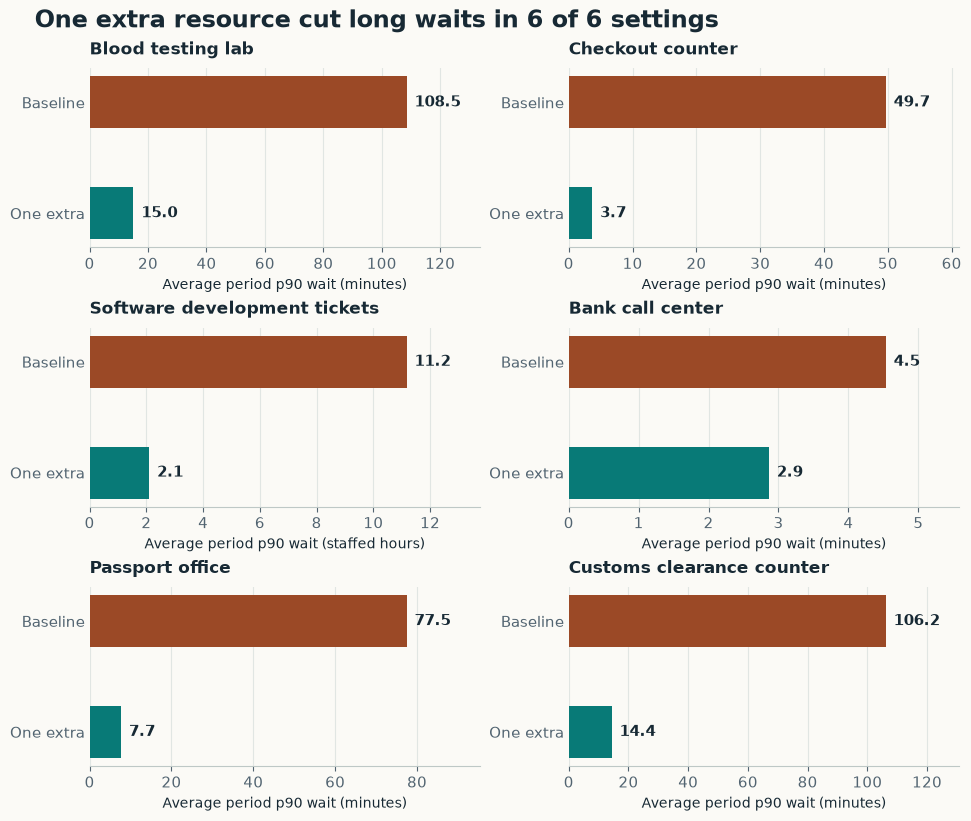

In [6]:
BASE_COLOR = "#9b4926"
EXTRA_COLOR = "#087a77"
INK = "#172934"
PAPER = "#fbfaf6"
SECONDARY = "#526471"

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "axes.spines.left": False, "axes.edgecolor": "#bec8c6",
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "text.color": INK, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "xtick.color": SECONDARY, "ytick.color": SECONDARY, "axes.titleweight": "bold",
    "grid.color": "#e1e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})


def plot_waits():
    fig, axes = plt.subplots(3, 2, figsize=(9.6, 8.1), layout="constrained")
    lower = int((effects.p90_change_min < 0).sum())
    fig.suptitle(f"One extra resource cut long waits in {lower} of {len(SCENARIOS)} settings",
                 fontsize=17, fontweight="bold", x=0.03, ha="left")
    for scenario, ax in zip(SCENARIOS, axes.flat, strict=True):
        scale = 60 if scenario.key == "software" else 1
        unit = "staffed hours" if scale == 60 else "minutes"
        rows = summary[summary.scenario == scenario.key].set_index("policy").reindex(POLICIES)
        values = rows.avg_p90_min.to_numpy() / scale
        finite_values = values[np.isfinite(values)]
        limit = max(finite_values.max(initial=0), 0.1)
        ax.set_xlim(0, limit * 1.23)
        ax.barh(0, values[0], height=0.47, color=BASE_COLOR)
        ax.barh(1, values[1], height=0.47, color=EXTRA_COLOR)
        ax.invert_yaxis()
        for position, value in enumerate(values):
            if np.isfinite(value):
                ax.text(value + limit * 0.025, position, f"{value:.1f}", va="center", fontweight="bold")
        ax.set_yticks([0, 1], POLICIES)
        ax.tick_params(axis="y", length=0)
        ax.set_title(scenario.name, loc="left", fontsize=12, pad=10)
        ax.set_xlabel(f"Average period p90 wait ({unit})", fontsize=10)
        ax.grid(axis="x")
    fig.savefig(FIGURES / "long-waits.png", dpi=135)
    plt.show()


def queue_series(run, stage_index, horizon):
    entered = run.enqueued[:, stage_index]
    left = run.started[:, stage_index].copy()
    if stage_index == 0:
        left[run.abandoned] = run.exited[run.abandoned]
    arrivals = np.sort(entered[np.isfinite(entered)])
    departures = np.sort(left[np.isfinite(left)])
    changes = np.unique(np.concatenate(([0, horizon], arrivals, departures)))
    times = changes[(changes >= 0) & (changes <= horizon)]
    length = np.searchsorted(arrivals, times, side="right") - np.searchsorted(departures, times, side="right")
    return times, length


def plot_queues(scenario):
    columns = len(scenario.stages)
    fig, axes = plt.subplots(1, columns, figsize=(9.6, 3.5), layout="constrained", squeeze=False)
    fig.suptitle(f"{scenario.name} | one matched operating period", x=0.03, ha="left",
                 fontsize=16, fontweight="bold")
    for stage_index, (stage, ax) in enumerate(zip(scenario.stages, axes[0], strict=True)):
        left, right = np.array(scenario.breaks[1:3]) / 60
        ax.axvspan(left, right, color="#e6e3d7", alpha=0.8, linewidth=0, label="Higher arrival rate")
        lines = []
        for policy, color, linestyle in [(BASELINE, BASE_COLOR, "-"), (EXTRA, EXTRA_COLOR, "--")]:
            run = example_runs[scenario.key, policy]
            times, length = queue_series(run, stage_index, scenario.horizon)
            line, = ax.step(times / 60, length, where="post", color=color, linestyle=linestyle,
                            linewidth=1.8, label=policy)
            lines.append(line)
        title = stage.name + (" (+1 here)" if stage_index == scenario.extra_stage else "")
        ax.set(title=title, xlabel="Hours since opening (staffed time)",
               ylabel=f"{scenario.count_label} waiting" if stage_index == 0 else "",
               xlim=(0, scenario.horizon / 60))
        ax.set_ylim(-0.3, max(1.3, ax.get_ylim()[1] + 0.3))
        ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.grid(axis="y")
    axes[0, 0].legend(handles=[*lines, axes[0, 0].patches[0]], loc="upper left", fontsize=9)
    fig.savefig(FIGURES / f"queue-{scenario.key}.png", dpi=135)
    plt.show()


plot_waits()

The biggest drop in minutes occurred in ticket review, where adding a reviewer removed more than nine staffed hours from the average period p90 across 11,298 simulated tickets. An eight-hour workday could pass between writing and reviewing a difficult-to-schedule ticket in the baseline. At checkout, a drop of about 46 minutes changes the experience from spending much of an hour in a line at the long-wait cutoff to spending only a few minutes. This comparison applies to the simulated shared line. A store that leaves customers to choose between separate lanes would add a routing decision.

The table gives the size of each drop. For the uncertainty interval, compute the extra-minus-baseline difference for each pair. Draw 240 pairs with replacement, calculate their mean difference, and repeat 4,000 times. The middle 95% of these means gives the interval. A negative difference means a shorter long-wait cutoff with added capacity. Resampling whole pairs keeps a busy period linked to its own baseline. The interval describes variation from simulating a finite set of periods under the same model.

| Setting | Arrivals across 240 periods | Baseline p90 | One extra p90 | Paired change and 95% interval |
| --- | ---: | ---: | ---: | --- |
| Blood testing lab | 44,479 | 108.5 min | 15.0 min | −93.5 min [−96.7, −90.2] |
| Checkout counter | 23,319 | 49.7 min | 3.7 min | −46.0 min [−49.3, −42.9] |
| Software development tickets | 11,298 | 11.17 staffed h | 2.10 staffed h | −9.07 staffed h [−9.72, −8.46] |
| Bank call center | 62,174 | 4.53 min | 2.86 min | −1.67 min [−1.75, −1.60] |
| Passport office | 24,089 | 77.5 min | 7.7 min | −69.8 min [−74.5, −65.1] |
| Customs clearance counter | 35,158 | 106.2 min | 14.4 min | −91.8 min [−100.2, −83.6] |

Each period carries equal weight in these p90 averages, so a busy day contributes one cutoff alongside a quiet day's cutoff. The effect for a caller who is answered is smaller in minutes than the other shift-length effects. The reason to look at the result differently is that 12,131 of 62,174 baseline callers hung up before service. They leave the queue early and contribute no answered-call wait. With an extra agent, 6,929 hung up and 55,245 got an answer. A policy evaluated solely on the answered-call p90 would miss much of the difference.

### Work left at closing

The number still in the system at closing captures the work an operation would have to clear, defer or hand off. This table includes jobs in service as well as jobs still waiting. The time to clear is the median across shifts, so a value of zero means at least half finished all jobs by the cutoff. Each policy continues working at its simulated staffing level after close to calculate this measure.

| Setting | Mean unfinished at close, baseline → one extra | Median additional time to clear, baseline → one extra |
| --- | ---: | ---: |
| Blood testing lab | 36.1 → 9.4 samples | 92.2 → 30.0 min |
| Checkout counter | 3.2 → 0.7 shoppers | 4.6 → 0.0 min |
| Software development tickets | 11.8 → 3.1 tickets | 9.74 → 2.26 staffed h |
| Bank call center | 2.98 → 2.97 calls | 9.80 → 9.49 min |
| Passport office | 9.2 → 1.6 applicants | 37.6 → 4.7 min |
| Customs clearance counter | 10.3 → 2.3 shipments | 127.4 → 10.9 min |

An additional customs inspector brings the median time to finish the work already admitted from over two hours to about 11 minutes. About 10 shipments are in the baseline system at close on average, compared with just over two under the second policy. Jobs that have finished clearance by that instant need no further work. Bank queues have about three calls still in the system either way. A lower rate of hanging up can coexist with a similar close count because calls can still be in progress when admissions stop. The short line and close count alone would give little indication of the fraction of callers who got help.

## 4. Six operating periods up close

The following queue timelines use period 1 in each setting. The solid rust line is baseline. The dashed teal line adds one resource where the title says "+1 here". The shaded window is the period of higher random arrival rates. The horizontal axis is staffed hours since opening. The vertical axis counts jobs waiting, with an independent scale for each stage. Jobs in service and callers who have already left are off the line.

These examples illustrate how the simulated rules produce the aggregate results. They include a normal immediate start, a job delayed at a second stage, a changed batch, a caller who is saved from hanging up and a priority queue that changes the order. Within each period, the named examples were selected after examining the outcomes. All input and outcome rows for those periods are available for comparison.

### Blood testing lab

Compare the accession line with the line of prepared samples waiting for a run. Accession is identical in both policies. Look for the sawtooth drops at the analyzer each time a set of samples leaves the queue to start processing.

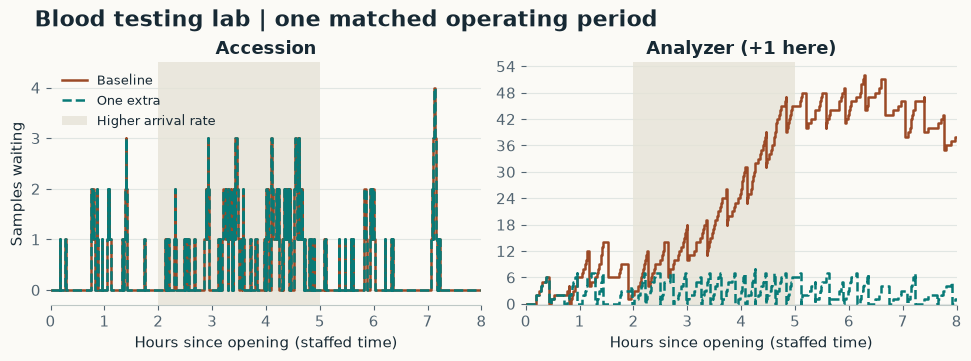

In [7]:
plot_queues(SCENARIO_BY_KEY["lab"])

During this period, 200 specimens came in. Up to four waited for accession at once. The single analyzer's queue reached 52 specimens and still had more than 30 waiting at the end of the chart. With a second analyzer it peaked at eight and 8 samples in total were unfinished at close, compared with 46 at baseline. The baseline stage spent 96% of its staffed analyzer-minutes running across all shifts. Its upper throughput at full batches is about 22 specimens per hour, compared with 34 arrivals per hour in the rush. The queue can carry that gap forward for the rest of the shift.

**End-to-end example.** Specimen `lab-001-075` arrived at minute 192.3 and required about 1.1 minutes of accession. Its arrival, accession requirement and 22-minute run were identical in both policies. All times in the table are measured from opening.

| Step | One analyzer | Two analyzers |
| --- | ---: | ---: |
| Sample arrives | 192.3 | 192.3 |
| Accession starts | 196.1 | 196.1 |
| Accession ends and sample joins analyzer line | 197.2 | 197.2 |
| Analyzer run starts | 245.9 | 205.4 |
| Run ends | 267.9 | 227.4 |
| Total queue wait | 52.5 min | 11.9 min |

With one analyzer the specimen waited 3.8 minutes for accession and 48.7 for analysis to begin. These add to its 52.5-minute wait. The 22-minute run adds to completion time. With two analyzers the same specimen finishes about 41 minutes earlier because its batch got an instrument sooner.

Batching can also give an individual specimen a longer wait. `lab-001-009` was ready at minute 46.3. In the one-analyzer run it joined a four-sample batch at 47.9, riding on the wait already accumulated by older samples. In the two-analyzer run those older samples had already formed a two-sample batch at minute 42.8. This specimen waited until eight ready samples accumulated at minute 57.5. Its queue wait increased from 1.7 to 11.3 minutes. Six of the 200 specimens in this example shift waited longer with two analyzers, even though that shift's p90 fell from 128.5 to 14.2 minutes. The effect comes from a change in which samples ride together under the timer rule.

### Checkout counter

Follow the shopper line as the rush begins at hour 2, then watch what happens after hour 5. Both policies keep shoppers in one shared line, so an open cashier can take the oldest waiting shopper.

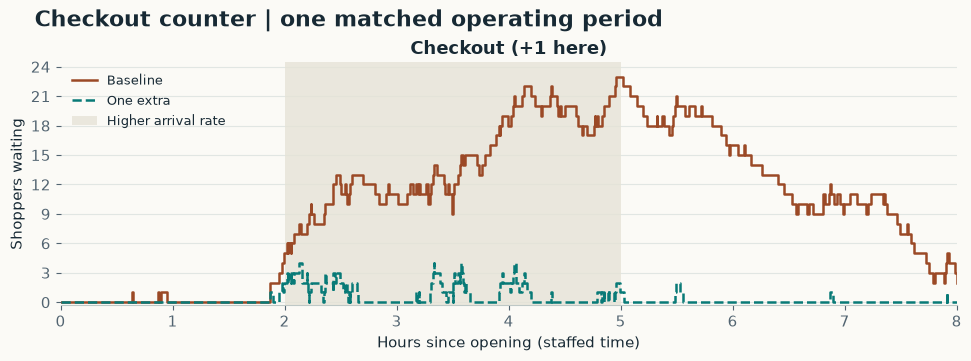

In [8]:
plot_queues(SCENARIO_BY_KEY["checkout"])

The baseline line reached 23 shoppers during the shift of 104 arrivals. It took much of the remaining shift to work through the line even after the arrival rate fell. With two cashiers, the peak was four and the queue returned to zero repeatedly. This is the delayed effect of a rush that supplies work faster than one cashier can process it. Continued arrivals can keep a draining queue above zero long after the peak.

At minute 31.4, shopper `checkout-001-001` started immediately in both policies. Their basket still took 7.2 minutes to scan and pay for. This shopper illustrates what the cashier can do when the system starts quiet. Shopper `checkout-001-020` arrived shortly after the rush began, at minute 131.8, with a 6.5-minute basket. Service started at minute 161.8 with one cashier and 133.0 with two. The extra counter changed the wait from 29.9 minutes to 1.1, with the same scanning and payment time. In this period, 98 of 104 shoppers waited less and six waited the same amount. A second cashier thus had room to help a large fraction of arrivals in the busy part of the period while having little effect on the first few quiet transactions.

### Software development tickets

Compare the two panels around staffed hour 25. Implementation uses three developers in both policies. The change happens when completed code enters the review line. A day on these axes represents eight staffed hours.

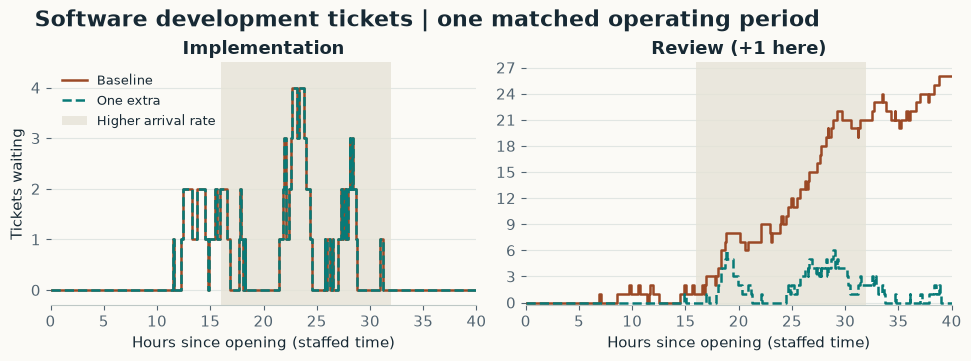

In [9]:
plot_queues(SCENARIO_BY_KEY["software"])

In this 60-ticket period, up to four tickets waited for implementation. The peak review line fell from 26 tickets with one reviewer to six with two. By hour 40 there were 28 unfinished tickets in the baseline and one with the extra reviewer. This period had a harsher baseline than the average of 11.8 unfinished tickets across all periods.

A routine ticket, `software-001-014`, arrived at about staffed hour 12.28. It waited 1.03 hours for a developer and spent 3.56 hours in implementation in both runs. It was ready for review at hour 16.87. With one reviewer it did not start review until hour 33.57, a wait of 16.70 hours for that stage alone. With two reviewers it entered review as soon as implementation finished. Its 17.6 minutes of review work were the same either way. The ticket illustrates how work can sit even after an earlier team has completed its part.

Urgency changes who bears a review bottleneck. Across all periods, 2,295 urgent tickets had a pooled p90 of 2.60 staffed hours with one reviewer, compared with 15.44 hours for 9,003 routine tickets. The second reviewer reduced these to 1.07 and 2.83 hours. Pooled figures put all members of a group in one list and take one cutoff, so larger periods contribute more jobs than smaller periods. These numbers describe this particular priority rule and the simulated mix of tickets. Implementation is still a source of delay. Its average period p90 remained about 66 minutes in both policies.

### Bank call center

A caller vanishes from the line either when an agent answers or when patience runs out. The chart counts everybody still waiting at the plotted instant. Compare the duration of the busy patches as well as their height.

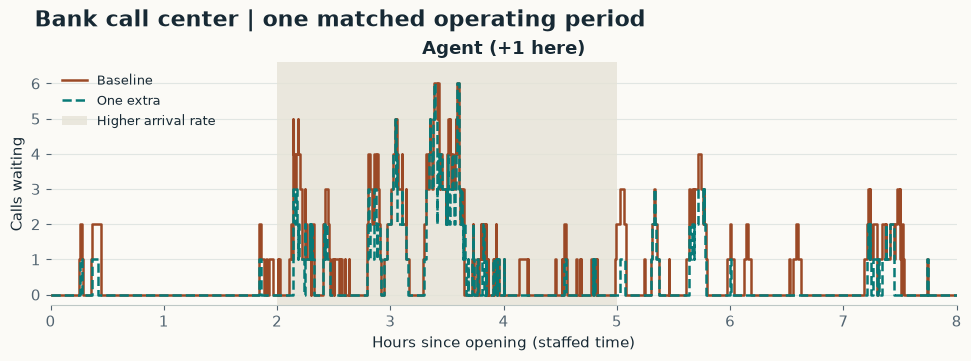

In [10]:
plot_queues(SCENARIO_BY_KEY["bank"])

The two curves reached six callers waiting in this 268-call shift. At close, three calls were in the system under either policy. With four agents, 43 callers hung up. With five, 18 did. A single line-length snapshot can miss the difference because it shows only the callers still present. The fifth agent changes which calls receive service even in a period where the maximum line length and end count look the same.

Caller `bank-001-016` arrived at minute 21.83 and would wait up to 4.88 minutes. With four agents the caller left at 26.72 without receiving service. The fifth agent allowed service to start at 25.17, about 1.55 minutes before the deadline. The call itself took 1.17 minutes. This caller enters the wait-time distribution only when answered. The 240 paired shifts used the same 62,174 callers and yielded a net increase of 5,202 answered calls. A staffing comparison that tracks answer rates can explain changes a chart of waits or line lengths alone leaves open.

The improvement also has a reverse case. In the third shift, `bank-003-125` called at minute 238.52 and was willing to wait until minute 242.31. Four agents answered at minute 242.13. Five agents were still busy at the deadline, so the same caller hung up. One of those agents had started a 20.3-minute call with `bank-003-113`, an earlier caller who hung up in the baseline. Answering earlier callers can keep capacity tied up when a later caller arrives. The full run had 5,366 calls that switched from abandoned to answered and 164 that switched in the other direction.

### Passport office

The plotted queue mixes applicants with appointments and walk-ins. A booked applicant waiting for a clerk can go ahead of an earlier walk-in. This rule is active with both two and three clerks.

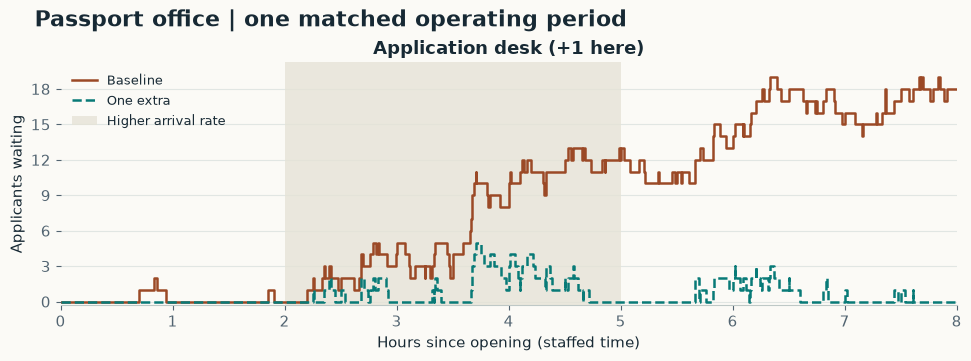

In [11]:
plot_queues(SCENARIO_BY_KEY["passport"])

The two-clerk queue reached 19 applicants in a shift of 103 arrivals. It was still elevated at hour 8, when 20 applicants were unfinished, including people being served. With three clerks, the queue reached five and one applicant was unfinished at closing. Priority is visible in individual starts. Walk-in `passport-001-007` arrived at minute 42.17. Booked applicant `passport-001-008` arrived at minute 50.00. At baseline the booked applicant got a desk at 51.70 and the walk-in started at 56.30. Both started immediately in the three-clerk run, in arrival order, because a desk was available for each.

The two groups have different experiences over 240 shifts. Across the 11,520 booked arrivals, the pooled p90 fell from 7.06 to 2.49 minutes. Across 12,569 walk-ins it fell from 114.56 to 12.60 minutes. Appointments kept their priority and arrived on evenly spaced slots throughout. Adding the third desk helps the people formerly waiting behind appointments more at the upper end of the distribution. The experiment holds both the slot spacing and priority fixed, so it gives an estimate for adding a desk under that rule.

### Customs clearance counter

Separate the queue that every shipment sees from the queue seen only by a referral. The added inspector can start a referred shipment sooner after primary clears it. Both policies keep two primary officers.

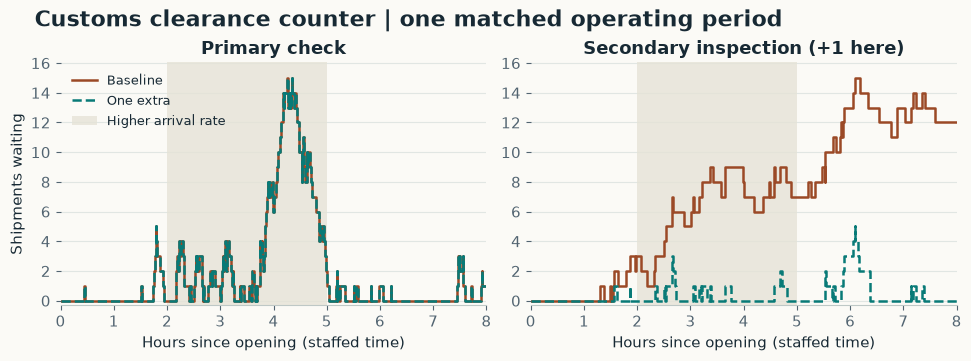

In [12]:
plot_queues(SCENARIO_BY_KEY["customs"])

In the 164-shipment example, the primary queue reached 15 shipments under both policies. A secondary queue grew during primary's rush and remained long after the arrival rate had fallen. It reached 15 with one inspector and five with two. This contrast shows how a surge can have consequences downstream. A shipment enters the secondary line only once it completes the primary service that the surge also affects.

Shipment `customs-001-038` needed both checks. It arrived at minute 133.28, began primary at 139.46 and finished that check at 149.71 either way. At baseline it waited another 55.14 minutes until secondary began. With a second inspector, that wait was about 1.54 minutes. Its total queue wait fell from 61.32 to 7.72 minutes. The work at both stages took the same time.

The 8,727 referred shipments in the full set had a pooled p90 wait of 211.42 minutes at baseline and 32.55 with the extra inspector. For the 26,431 primary-only shipments, the same jobs passed through the same primary queue and the pooled p90 stayed at 9.31 minutes. The effect in the combined result comes entirely through the referred group. This distinction matters to someone deciding where to add capacity. If they only handle primary traffic, the extra inspector assigned to the other stage leaves their queue time exactly as before.

### How often did an individual wait move?

A period's p90 can improve even if some people wait longer. Pairing job IDs lets us check how often this happened. The table compares waiting only for jobs served under both policies. It treats answers and hang-ups as separate outcomes, as in the bank example.

| Setting | Served in both runs | Shorter wait | Same wait | Longer wait |
| --- | ---: | ---: | ---: | ---: |
| Blood testing lab | 44,479 | 40,619 | 1,627 | 2,233 |
| Checkout counter | 23,319 | 19,546 | 3,773 | 0 |
| Software development tickets | 11,298 | 9,478 | 1,679 | 141 |
| Bank call center | 49,879 | 19,200 | 29,519 | 1,160 |
| Passport office | 24,089 | 19,019 | 4,214 | 856 |
| Customs clearance counter | 35,158 | 7,677 | 27,481 | 0 |

The lab's 2,233 longer waits are about 5% of its specimens. An added analyzer changes the composition and timing of batches, as the specimen example shows. At checkout every job that waited a different length of time waited less. The checkout has a shared first-come line, no other stage and no abandonment or batching. In customs, most waits stayed the same. This includes all 26,431 primary-only clearances and some of the referrals. An average improvement describes the queue under the tested rule. The paired job counts show how often a particular person or job experienced it.

## 5. What the comparison can support

There are 200,517 generated arrivals across all six settings, paired between policies. That count describes the volume of work simulated. The independently generated periods, rather than the individual jobs that share a line, are the units used for the interval. The analysis design and original outcomes are recorded in the [protocol](data/PROTOCOL.md), including the later inspection of job-level exceptions.

The most consequential inputs are the arrival peaks, the mix and distribution of service durations, and which stages can share capacity. They are chosen assumptions. The effect of a fifth call agent would change if patience varied with time of day, if customers called back, or if agents had different skills. A bank queue where callers stay on hold longer could show a higher answered-call p90 with a different abandonment rate. Estimating both requires data on the time callers actually waited and whether service or hanging up ended each wait.

The lab grants each of the additional analyzers immediate access to prepared samples without making the analyst who loads it a separate resource. A real lab that shares equipment and staff across tests could reach a different limit first. The customs rule draws referrals independently of how long primary service takes, and referrals never block the primary stage. A shared space or staff constraint could couple those queues. At the passport office all bookings arrive on time. Staff breaks and missed or early appointments could change how much of the time the extra desk would be used.

The simulations start empty. They admit work during the stated window and then stop accepting arrivals. Clearance after the window assumes the same resources stay available. A lab that carries specimens into the next morning or a development team that starts Monday with tickets already waiting would face a different initial workload. The study neither values those extra staffed hours in dollars nor models the staffing schedule that makes them possible. An extra eight-hour cashier and an extra 40-hour reviewer also represent different labour commitments, so cross-setting differences in waiting time cannot establish a return per worker-hour.

Within these assumptions, putting one resource where the model has a long line can sharply reduce time spent waiting. The six paired simulations give specific examples of where the gains went. The checkout line almost cleared by closing with two cashiers. The added reviewer and secondary inspector reduced unfinished work while their upstream paths stayed fixed. The bank's main visible gain came from more callers receiving an answer. Variation across resources, groups and outcomes matters when choosing which queue to observe before making a real staffing change.

## 6. How to reproduce

Open [the notebook](47_queue_simulations.ipynb) and run it from its own folder using the repository's Python environment. It uses NumPy to draw the inputs, pandas to summarize them, and matplotlib to draw the figures. The notebook defines its own simulator and executes offline. The budget is USD 0 for external calls.

```powershell
python -m pip install -r ../../requirements.txt
python -m nbconvert --to notebook --execute --inplace 47_queue_simulations.ipynb
```

The setup cell contains the seed, number of periods, arrival rates, service distributions and staffing. Change them in a copy to try another rush or resource configuration. Re-running with the recorded settings regenerates the tables and figures. The explanatory examples and written results document the original settings. The executed notebook also prints the computed result tables so a reader can see the outcome of a different configuration.

- [Period results](data/period_results.csv) give one record per setting, period and policy. [Stage results](data/stage_results.csv) show queue waits, utilization, and lab batch counts.
- [Summary](data/summary.csv) and [paired effects](data/paired_effects.csv) aggregate by setting and policy. [Group results](data/groups.csv) show pooled waits for urgent and routine tickets, appointments and walk-ins, and primary-only and referred shipments. [Matched job changes](data/job_changes.csv) count how often an individual wait or call outcome moved.
- [Example inputs](data/example_inputs.csv), [example outcomes](data/example_outcomes.csv) and [example batches](data/example_batches.csv) let you follow the six plotted periods and the first bank shift with a call that switched from answered to abandoned. The same job ID joins each input to both policy rows. A blank second-stage time means the job did not visit that stage. A blank first-stage start on a bank outcome means the caller hung up.
- [Protocol](data/PROTOCOL.md) records the run design, exact clock conventions and environment.

The computed tables below let you check the outcome if you change the setup. The policy rows group the overall measures by staffing level. The effects table uses minutes throughout and counts the pairs with a lower period p90.

In [13]:
display(summary.loc[:, ["scenario", "policy", "arrivals", "served", "abandonment_pct",
                        "avg_p90_min", "avg_unfinished"]].round(2))
display(effects.round(2))
print("Cost: USD 0. All inputs and queue paths are computed locally.")

,scenario,policy,arrivals,served,abandonment_pct,avg_p90_min,avg_unfinished
0,lab,Baseline,44479,44479,0.00,108.51,36.09
1,lab,One extra,44479,44479,0.00,15.02,9.39
2,checkout,Baseline,23319,23319,0.00,49.68,3.24
3,checkout,One extra,23319,23319,0.00,3.66,0.65
4,software,Baseline,11298,11298,0.00,670.34,11.82
5,software,One extra,11298,11298,0.00,125.93,3.10
6,bank,Baseline,62174,50043,19.51,4.53,2.98
7,bank,One extra,62174,55245,11.14,2.86,2.97
8,passport,Baseline,24089,24089,0.00,77.46,9.25
9,passport,One extra,24089,24089,0.00,7.69,1.62


,scenario,paired_periods,p90_change_min,ci_low_min,ci_high_min,periods_p90_lower
0,lab,240,-93.49,-96.74,-90.17,240
1,checkout,240,-46.02,-49.35,-42.91,240
2,software,240,-544.40,-583.00,-507.62,240
3,bank,240,-1.67,-1.75,-1.60,240
4,passport,240,-69.77,-74.46,-65.08,240
5,customs,240,-91.82,-100.17,-83.65,240


Cost: USD 0. All inputs and queue paths are computed locally.


The period tables in the data folder preserve the individual pairs behind these averages, including the six operating periods shown in the timelines.

## 7. Future work and further reading

### Future work

- Add the same number of worker-hours only during the rush and compare the period p90 and close backlog with full-shift coverage. The checkout and bank traces show why the timing of the extra hours could matter.
- Sweep the analyzer's maximum batch hold with one and with two analyzers. Record specimens per batch, instrument occupancy and total elapsed time to completion. The partial batches in the faster lab raise a tradeoff between waiting for a full batch and making a machine available again.
- Add ticket-review rework and a limited pool of engineers shared between implementation and review. Measure urgent and routine p90 separately and vacant review capacity. The two-resource intervention reduced the review line while leaving the implementation queue in the model.
- Compare two passport priority rules with measured lateness and no-shows. Measure missed appointment windows and walk-in p90. The fixed-slot experiment leaves an open question about how much policy and capacity each contribute to the difference between groups.
- Try the extra customs officer at primary instead of secondary, then vary the referral share and allow referrals to be concentrated among longer primary checks. Compare the p90 for referred shipments and close backlog. The unchanged primary line in the current comparison makes placement a question worth testing.

### Further reading

Links checked on 2026-11-18.

- [Stochastic Processes: Theory for Applications](https://ocw.mit.edu/courses/6-262-discrete-stochastic-processes-spring-2011/resources/6_262_s_11_coursetextbookpdf_pdf/) (Gallager, 2011 MIT course edition). The text develops Poisson arrivals and explains the relationship between load and waiting in basic queue models.
- [A Proof for the Queuing Formula L = λW](https://doi.org/10.1287/opre.9.3.383) (Little, 1961). The formula links long-run average occupancy, arrival rate and time spent in a system. The finite windows in this notebook start empty and use explicit job accounting.
- [Designing a Call Center with Impatient Customers](https://pubsonline.informs.org/doi/abs/10.1287/msom.4.3.208.7753) (Garnett et al., 2002). This paper analyzes a queue with a pool of agents and callers with exponential patience.
- [To Wait or Not to Wait: Two-way Functional Hazards Model for Understanding Waiting in Call Centers](https://arxiv.org/abs/1801.00344) (Li et al., 2017 preprint). The paper fits willingness to wait as a function of the time already on hold and the time of day using bank call center records.